# Cloud Workload Forecasting - Data Exploration

Goal: understand the VM workload before forecasting the two targets
(`active_vm_count` and `aggregate_cpu_utilization`).

Rule: I check data quality on the full dataset.
I study patterns on the first 110 timestamps only.
I never look at the last 24 timestamps (holdout).

## 1. Load the data

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Find the data folder whether the notebook runs from the project root or from notebooks/
data_dir = Path("challenge_data")
if not data_dir.exists():
    data_dir = Path("../challenge_data")

cpu = pd.read_csv(data_dir / "vm_cpu_readings.csv.gz")
meta = pd.read_csv(data_dir / "vm_metadata.csv.gz")

print(cpu.shape, meta.shape)
display(cpu.head(), meta.head())
print(cpu.dtypes, meta.dtypes, sep="\n\n")

(1340000, 5) (10000, 11)


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4
3,88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...,4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...,yfPM2qpoqC9aXMgM7S0mCLxCY8NEd4C6uiLpfY443SV5Yj...,0,70200,98.738842,81.578650,98.439173,Unknown,4,8
4,C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...,1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...,hrP166UPejKeASJ3ibhQ68YrE7iDxsmlXNZ2B8BBy0BMKn...,0,2591400,90.790129,2.382323,6.902215,Delay-insensitive,2,4


timestamp      int64
vm_id            str
min_cpu      float64
max_cpu      float64
avg_cpu      float64
dtype: object

vm_id                       str
subscription_id             str
deployment_id               str
timestamp_vm_created      int64
timestamp_vm_deleted      int64
max_cpu                 float64
avg_cpu                 float64
p95_max_cpu             float64
vm_category                 str
virtual_core_bucket         str
memory_gb_bucket            str
dtype: object


**What I see:** 1,340,000 readings for 10,000 VMs. Metadata has 11 columns. Timestamps are in seconds and start at 0.

## 2. Time grid and coverage
Is there one reading every 5 minutes? Does every VM report at every timestamp?
This matters because gaps would change both targets.

In [2]:
# Sorted list of all timestamps in the dataset
timestamps = pd.Series(sorted(cpu["timestamp"].unique()))
print("Distinct timestamps:", len(timestamps))
print("Gaps between timestamps (seconds):", timestamps.diff().value_counts().to_dict())
print("Distinct VMs:", cpu["vm_id"].nunique())

# Coverage: VMs per timestamp, and timestamps per VM
vms_per_timestamp = cpu.groupby("timestamp")["vm_id"].nunique()
timestamps_per_vm = cpu.groupby("vm_id")["timestamp"].nunique()
print(vms_per_timestamp.describe())
print(timestamps_per_vm.describe())

Distinct timestamps: 134
Gaps between timestamps (seconds): {300.0: 133}
Distinct VMs: 10000
count      134.0
mean     10000.0
std          0.0
min      10000.0
25%      10000.0
50%      10000.0
75%      10000.0
max      10000.0
Name: vm_id, dtype: float64
count    10000.0
mean       134.0
std          0.0
min        134.0
25%        134.0
50%        134.0
75%        134.0
max        134.0
Name: timestamp, dtype: float64


**What I see:** 134 timestamps, exactly 300 seconds apart, no gap. All 10,000 VMs report at every timestamp. The grid is complete.

## 3. Missing values, duplicates, invalid values
A duplicate would count a VM twice. A wrong CPU value would shift the average.
I use these checks to define a "valid observation".

In [3]:
print("Null values:\n", cpu.isna().sum())

# Duplicates on the (vm_id, timestamp) key
duplicate_keys = cpu.duplicated(["vm_id", "timestamp"], keep=False)
print("Rows with a duplicated (vm_id, timestamp):", duplicate_keys.sum())
print("Exact duplicate rows:", cpu.duplicated().sum())

# Value checks
out_of_range = ~cpu["avg_cpu"].between(0, 100)
wrong_order = (cpu["min_cpu"] > cpu["avg_cpu"]) | (cpu["avg_cpu"] > cpu["max_cpu"])
print("avg_cpu outside [0, 100] or null:", out_of_range.sum())
print("min > avg or avg > max:", wrong_order.sum())
print(cpu[["min_cpu", "avg_cpu", "max_cpu"]].describe())

Null values:
 timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64
Rows with a duplicated (vm_id, timestamp): 0
Exact duplicate rows: 0
avg_cpu outside [0, 100] or null: 0
min > avg or avg > max: 0
            min_cpu       avg_cpu       max_cpu
count  1.340000e+06  1.340000e+06  1.340000e+06
mean   6.156478e+00  9.388101e+00  1.834830e+01
std    1.175525e+01  1.426601e+01  2.161651e+01
min    0.000000e+00  7.158922e-03  1.810795e-02
25%    1.487979e+00  2.477060e+00  4.417642e+00
50%    3.227996e+00  5.105133e+00  9.124204e+00
75%    5.331087e+00  9.616715e+00  2.362418e+01
max    9.928158e+01  9.948803e+01  9.970286e+01


**What I see:** No missing values, no duplicates, no value outside 0-100, and min <= avg <= max on every row.
My rule: a valid observation is one row per (vm_id, timestamp) with avg_cpu between 0 and 100.
No cleaning is needed here, but I keep these checks in the pipeline in case the input data changes.

## 4. Training window and first look at the targets
Training = first 110 timestamps. Everything below uses training data only.

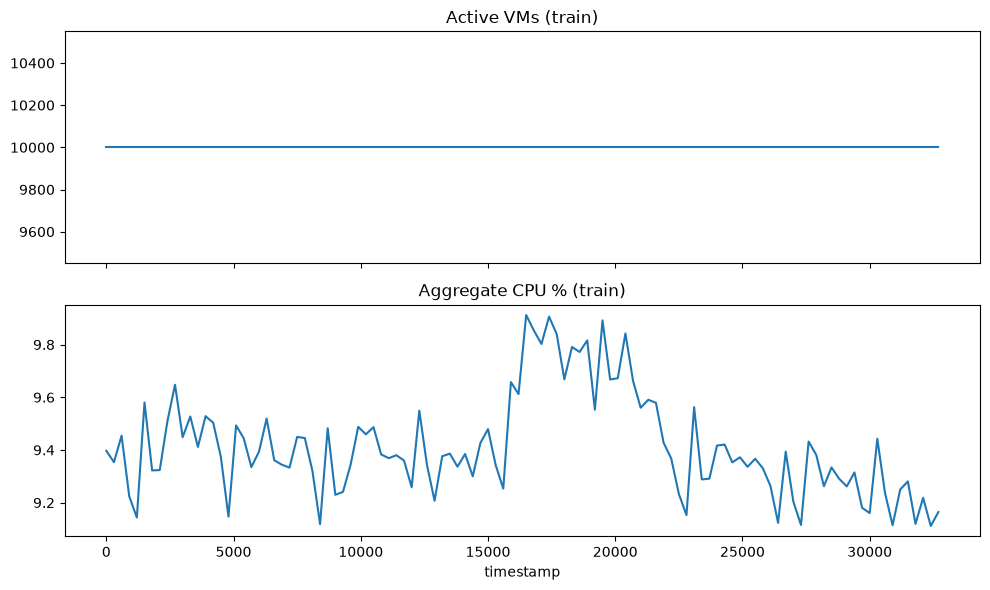

       active_vm_count  aggregate_cpu
count            110.0     110.000000
mean           10000.0       9.414089
std                0.0       0.193568
min            10000.0       9.111634
25%            10000.0       9.288952
50%            10000.0       9.378121
75%            10000.0       9.507673
max            10000.0       9.912175


In [4]:
# Training window: first 110 timestamps
train_timestamps = timestamps.iloc[:110]
train = cpu[cpu["timestamp"].isin(train_timestamps)]

# Preliminary target series
targets = train.groupby("timestamp").agg(
    active_vm_count=("vm_id", "nunique"),
    aggregate_cpu=("avg_cpu", "mean"),
)

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
targets["active_vm_count"].plot(ax=ax[0], title="Active VMs (train)")
targets["aggregate_cpu"].plot(ax=ax[1], title="Aggregate CPU % (train)")
plt.tight_layout()

# Save the figure for the final report
figures_dir = data_dir.parent / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figures_dir / "targets_train.png", dpi=150, bbox_inches="tight")

plt.show()
print(targets.describe())

**What I see:** The VM count is flat at 10,000. Aggregate CPU stays between 9.1% and 9.9% (mean 9.4, std 0.19).
There is one bump of about +0.4 points between t=16,000 and t=22,000, then the level comes back down.
I see no repeating pattern in these 9 hours.

## 5. VM lifetimes
Do VMs start or stop during the window?
This matters because it changes the number of active VMs.

In [5]:
# First and last reading of each VM inside the training window
lifetimes = train.groupby("vm_id")["timestamp"].agg(["min", "max", "count"])
print("Share of VMs present from the start:", (lifetimes["min"] == train_timestamps.iloc[0]).mean())
print("Share of VMs present until the end of train:", (lifetimes["max"] == train_timestamps.iloc[-1]).mean())
print(lifetimes["count"].describe())

arrivals = lifetimes["min"].value_counts().sort_index()
departures = lifetimes["max"].value_counts().sort_index()
print("First readings per timestamp:\n", arrivals.head(10))
print("Last readings per timestamp:\n", departures.tail(10))
print(meta[["timestamp_vm_created", "timestamp_vm_deleted"]].describe())

Share of VMs present from the start: 1.0
Share of VMs present until the end of train: 1.0
count    10000.0
mean       110.0
std          0.0
min        110.0
25%        110.0
50%        110.0
75%        110.0
max        110.0
Name: count, dtype: float64
First readings per timestamp:
 min
0    10000
Name: count, dtype: int64
Last readings per timestamp:
 max
32700    10000
Name: count, dtype: int64
       timestamp_vm_created  timestamp_vm_deleted
count               10000.0          1.000000e+04
mean                    0.0          2.289626e+06
std                     0.0          7.081008e+05
min                     0.0          4.050000e+04
25%                     0.0          2.591400e+06
50%                     0.0          2.591400e+06
75%                     0.0          2.591400e+06
max                     0.0          2.591400e+06


**What I see:** No VM starts or stops in the training window. All VMs are created at t=0 and the earliest deletion (40,500 s) is after the end of the trace.
The dataset keeps only VMs with a complete trace, so real churn is not visible. This is a limit: in production the VM count would move.

## 6. CPU distribution
Are most VMs idle or busy?
This matters because a few busy VMs can drive the average.

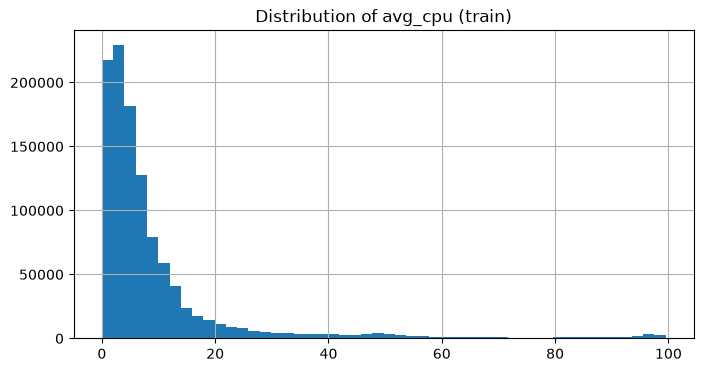

0.05     0.776256
0.25     2.486945
0.50     5.119809
0.75     9.647974
0.95    37.293248
0.99    87.406347
Name: avg_cpu, dtype: float64
Share of VMs with mean CPU below 5%: 0.4635
Share of VMs with mean CPU above 50%: 0.022


In [6]:
train["avg_cpu"].hist(bins=50, figsize=(8, 4))
plt.title("Distribution of avg_cpu (train)")
plt.show()
print(train["avg_cpu"].quantile([0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

# Mean CPU per VM
mean_cpu_per_vm = train.groupby("vm_id")["avg_cpu"].mean()
print("Share of VMs with mean CPU below 5%:", (mean_cpu_per_vm < 5).mean())
print("Share of VMs with mean CPU above 50%:", (mean_cpu_per_vm > 50).mean())

**What I see:** Most VMs are almost idle. The median reading is 5.1% and 46% of VMs average below 5%.
Only 2.2% of VMs average above 50%, but the 99th percentile is 87%.
The mean (9.4%) is almost twice the median, so a small group of busy VMs drives the aggregate.

## 7. Differences between segments
I compare CPU by category, core count and memory size.
Different segments may need different capacity rules.

Rows without metadata: 0
                    vms   mean_cpu
vm_category                       
Delay-insensitive  6180   8.257266
Interactive        3091  11.505150
Unknown             729  10.354689
                      vms   mean_cpu
virtual_core_bucket                 
2                    7534   9.764163
24                     62  11.428831
4                    1908   7.918723
8                     486   9.658399
>24                    10   6.619469
                   vms   mean_cpu
memory_gb_bucket                 
2                 3904   8.802254
32                1383   7.814017
4                 2475  11.459541
64                  82  11.217160
8                 2146   9.143401
>64                 10   6.619469


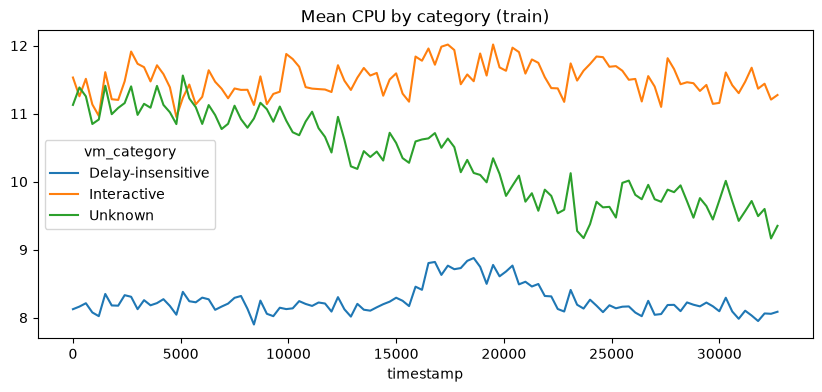

In [7]:
segment_columns = ["vm_category", "virtual_core_bucket", "memory_gb_bucket"]
train_with_meta = train.merge(meta[["vm_id"] + segment_columns], on="vm_id", how="left")
print("Rows without metadata:", train_with_meta["vm_category"].isna().sum())

for column in segment_columns:
    print(train_with_meta.groupby(column).agg(vms=("vm_id", "nunique"), mean_cpu=("avg_cpu", "mean")))

train_with_meta.groupby(["timestamp", "vm_category"])["avg_cpu"].mean().unstack().plot(figsize=(10, 4))
plt.title("Mean CPU by category (train)")
plt.show()

**What I see:** Interactive VMs run hotter (11.5%) than delay-insensitive VMs (8.3%, 62% of the fleet).
The bump comes from the delay-insensitive group. The unknown group drifts down from about 11% to 9.5%.
The ">24 cores" and ">64 GB" buckets have only 10 VMs, too few to conclude anything.

## 8. Peaks and lows
Capacity is sized for peaks, so I look at the highest-load moments.

5 highest-load timestamps:
 timestamp
16500    9.912175
17400    9.906192
19500    9.891946
16800    9.853998
20400    9.842210
Name: aggregate_cpu, dtype: float64
5 lowest-load timestamps:
 timestamp
32400    9.111634
30900    9.114320
27300    9.115401
8400     9.118488
31800    9.119565
Name: aggregate_cpu, dtype: float64


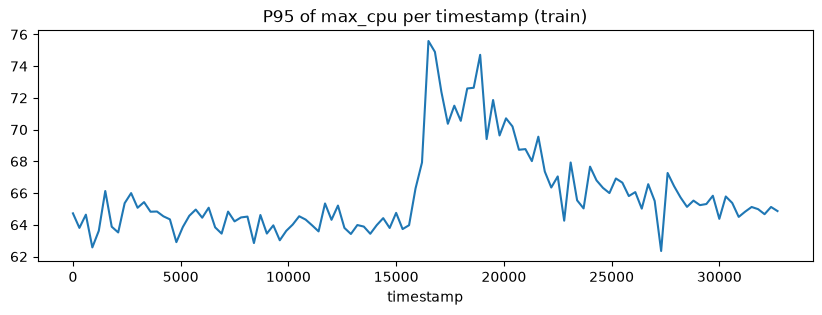

Standard deviation of aggregate CPU: 0.19356833547362823


In [8]:
print("5 highest-load timestamps:\n", targets["aggregate_cpu"].nlargest(5))
print("5 lowest-load timestamps:\n", targets["aggregate_cpu"].nsmallest(5))

# 95th percentile of max_cpu across VMs, per timestamp
p95_max_cpu = train.groupby("timestamp")["max_cpu"].quantile(0.95)
p95_max_cpu.plot(figsize=(10, 3), title="P95 of max_cpu per timestamp (train)")
plt.show()
print("Standard deviation of aggregate CPU:", targets["aggregate_cpu"].std())

**What I see:** The highest load is between t=16,500 and t=20,400.
The average moves by only 0.4 points, but the P95 of max_cpu jumps from about 64% to 75%.
Peaks are much more visible in the tail than in the average.

## 9. Summary: what this means for the model

- `active_vm_count` is constant, so the forecast is the last value. The dataset design explains this.
- `aggregate_cpu_utilization` moves in a very narrow band (std 0.19). A simple baseline will be hard to beat.
- 110 points and no seasonality: simple models only. Complex models would overfit.
- Segments behave differently, so forecasting per category and summing is worth testing.
- Capacity should follow the tail (P95 of max_cpu), not the average.